# Imports

In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

# Loading env variables

In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="your-lm-studio-model-id",
    base_url="http://localhost:1234/v1",
    api_key="lm-studio",  # Placeholder; LM Studio usually doesn't require a real API key
)

# Define LLM

In [3]:
model = llm

# Define State

In [4]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

# Creating Nodes

In [5]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [6]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

# Define and Compile Graph

In [7]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()


# Execute the Graph

In [8]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': 'Here is a comprehensive and structured outline for a long-form blog post titled **"The Rise of AI in India: From Digital Ambition to Global Leader."** This outline is designed to cover history, policy, industry impact, challenges, and future trends.\n\n---\n\n# Blog Post Outline: The Rise of AI in India\n\n## **I. Title Options**\n*   *Option 1:* The Rise of AI in India: How the Subcontinent is Reshaping the Tech Landscape.\n*   *Option 2:* Artificial Intelligence in India: Opportunities, Challenges, and the Path Forward.\n*   *Option 3:* Beyond Code: The Complete Guide to India\'s AI Revolution (2024 Edition).\n\n## **II. Meta Data**\n*   **Target Audience:** Tech professionals, Investors, Policy makers, Students, General Readers.\n*   **Tone:** Informative, Optimistic, Analytical, Forward-looking.\n*   **Word Count Estimate:** 2,500 – 3,500 words.\n*   **Key Keywords:** AI in India, National AI Mission, Digital Public Infrastructure, Start

In [9]:
print(final_state['outline'])

Here is a comprehensive and structured outline for a long-form blog post titled **"The Rise of AI in India: From Digital Ambition to Global Leader."** This outline is designed to cover history, policy, industry impact, challenges, and future trends.

---

# Blog Post Outline: The Rise of AI in India

## **I. Title Options**
*   *Option 1:* The Rise of AI in India: How the Subcontinent is Reshaping the Tech Landscape.
*   *Option 2:* Artificial Intelligence in India: Opportunities, Challenges, and the Path Forward.
*   *Option 3:* Beyond Code: The Complete Guide to India's AI Revolution (2024 Edition).

## **II. Meta Data**
*   **Target Audience:** Tech professionals, Investors, Policy makers, Students, General Readers.
*   **Tone:** Informative, Optimistic, Analytical, Forward-looking.
*   **Word Count Estimate:** 2,500 – 3,500 words.
*   **Key Keywords:** AI in India, National AI Mission, Digital Public Infrastructure, Startups, Generative AI, Data Privacy, Government Policy.

---

##

In [10]:
print(final_state['content'])

# The Rise of AI in India: From Digital Ambition to Global Leader

## **Meta Data**
*   **Target Audience:** Tech professionals, Investors, Policy makers, Students, General Readers.
*   **Tone:** Informative, Optimistic, Analytical, Forward-looking.
*   **Word Count Estimate:** 3,000+ words.
*   **Key Keywords:** AI in India, National AI Mission, Digital Public Infrastructure, Startups, Generative AI, Data Privacy, Government Policy.

---

# I. Introduction: The Great Shift

For decades, the image of "Tech India" was synonymous with the back-of-the-office reality: rows of engineers wearing blue shirts and headsets, managing call centers, or writing code for global giants. This era defined the country’s first technological leap—a service-oriented economy that built its wealth on intellectual labor but rarely owned the underlying assets. The world saw India as a "service hub" for the West, providing efficiency at scale.

Today, however, the narrative is undergoing a seismic transformatio

# Visualize Graph (Optional)

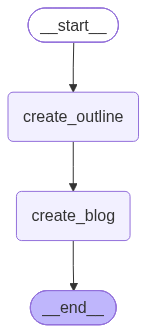

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())